1. IMPORTS

In [2]:
# importing
import sys
import importlib
from pathlib import Path
import os
import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nx
import lightgbm as lgb
import thrember

AQUA_path = "/Users/angela/aqua"
if AQUA_path not in sys.path:
    sys.path.insert(0, AQUA_path)

importlib.invalidate_caches()

import aqua
from aqua.configs import main_config
from aqua.data import Aqdata
from aqua.models.presets import AqNet
from aqua.models.cleaning_modules.aum.aum import AUM
print("done")

/Users/angela/miniforge3/envs/aqua311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Disabling PyTorch because PyTorch >= 2.6 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
[nltk_data] Downloading package punkt to /Users/angela/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/angela/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


done


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch imported")

x = torch.randn(8, 2568)

print("Tensor created:", x.shape)

PyTorch version: 2.2.2
PyTorch imported
Tensor created: torch.Size([8, 2568])


2. CONFIGURATION

In [4]:
# configuring
main_config["device"] = "cpu"

resultdirect_APK = Path("/Users/angela/aqua_results_APK")

resultdirect_APK.mkdir(parents=True, exist_ok=True)

main_config["results_dir"] = str(resultdirect_APK)

# REPRODUCIBILITY
SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Configuration")

Configuration


2. LOADING DATA

In [5]:
# LOADING DATA

import numpy as np
import os

data_APK = "/Users/angela/new_ember_apk_ss"

X_train_APK = np.memmap(
    os.path.join(data_APK, "X_train.dat"),
    dtype=np.float32,
    mode="r",
    shape=(52000, 2568)   
)

y_train_APK = np.memmap(
    os.path.join(data_APK, "y_train.dat"),
    dtype=np.int32,
    mode="r",
    shape=(52000,)
)
X_APK_train = np.asarray(X_train_APK[:41600])
y_APK_train = np.asarray(y_train_APK[:41600])

x_APK_val = np.asarray(X_train_APK[41600:])
y_APK_val = np.asarray(y_train_APK[41600:])

# testing 

X_test_APK = np.memmap(
    os.path.join(data_APK, "X_test.dat"),
    dtype = np.float32,
    mode="r",
    shape=(12000,2568)
)

y_test_APK = np.memmap(
    os.path.join(data_APK, "y_test.dat"),
    dtype=np.int32,
    mode="r",
    shape=(12000,)
)

print("Features", X_train_APK.shape)
print("Labels:", y_train_APK.shape)
print("Label counts: ", np.unique(y_train_APK, return_counts=True))


Features (52000, 2568)
Labels: (52000,)
Label counts:  (array([0, 1], dtype=int32), array([26060, 25940]))


In [6]:
print("Training:", X_APK_train.shape)
print("Validation:", x_APK_val.shape)
print("Testing:", X_test_APK.shape)

print("Training labels:", y_APK_train.shape)
print("Validation labels:", y_APK_val.shape)
print("Testing labels:", y_test_APK.shape)

print("Label counts:", np.unique(y_APK_train, return_counts=True))

Training: (41600, 2568)
Validation: (10400, 2568)
Testing: (12000, 2568)
Training labels: (41600,)
Validation labels: (10400,)
Testing labels: (12000,)
Label counts: (array([0, 1], dtype=int32), array([20883, 20717]))


3. SCALING

In [7]:
# scaling
from sklearn.preprocessing import StandardScaler

scaling_APK = StandardScaler()

X_APK_train_sc = scaling_APK.fit_transform(X_APK_train).astype(np.float32)
X_APK_val_sc = scaling_APK.transform(x_APK_val).astype(np.float32)
X_APK_test_sc = scaling_APK.transform(X_test_APK).astype(np.float32)


In [8]:
print(X_APK_train_sc.shape)
print(X_APK_val_sc.shape)
print(X_APK_test_sc.shape)

(41600, 2568)
(10400, 2568)
(12000, 2568)


intitializing the aqua data

In [9]:
DataQ_AQUA_APK = Aqdata(
    X_APK_train_sc.astype(np.float32),
    y_APK_train.astype(np.int64),
    noise_rate=0.0
)
print(DataQ_AQUA_APK.data.shape)

(41600, 2568)


In [10]:
print("Features:", X_APK_train_sc.shape)
print("Labels:", y_APK_train.shape)

Features: (41600, 2568)
Labels: (41600,)


In [11]:
import inspect
print(inspect.signature(Aqdata))

(data, ground_labels, **kwargs)


AUM - COMPATIBLE

In [12]:
print(torch.__version__)
print(torch.cuda.is_available())
x = torch.randn(8,2568)
print(x.shape)


2.2.2
False
torch.Size([8, 2568])


In [13]:
import torch
import torch.nn as nn

model_test = nn.Sequential(
    nn.Linear(2568, 512),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 3)
)

x = torch.randn(8, 2568)
y = model_test(x)

print("Complete MLP works:", y.shape)

Complete MLP works: torch.Size([8, 3])


In [14]:


class AUMCompatibleMLP_APK(nx.Module):
    def __init__(s, i_dim, o_dim=3):
        super().__init__()
        s.network = nx.Sequential(
            nx.Linear(i_dim, 512),
            nx.ReLU(),
            nx.Dropout(0.2),
            nx.Linear(512, 128),
            nx.ReLU(),
            nx.Dropout(0.2),
            nx.Linear(128,o_dim)
        )
    def forward(s,x, kwargs=None):
        return s.network(x)

AUM_M_APK = AUMCompatibleMLP_APK(i_dim=2568, o_dim=3)

t_in_APK = torch.randn(8,2568)
t_out_APK = AUM_M_APK(t_in_APK)
print(t_out_APK.shape)

torch.Size([8, 3])


In [15]:
optimizing_APK = torch.optim.Adam(
    AUM_M_APK.parameters(),
    lr=0.001
)
print("done")

done


AQNET

In [16]:
import aqua.models.presets as pres
import aqua.models.cleaning_modules.aum.aum as aum_module
from torch.utils.data.dataloader import DataLoader as OriginalDataLoader

def DLZW(*args, **kwargs):
    kwargs["num_workers"]=0
    return OriginalDataLoader(*args, **kwargs)

pres.DataLoader = DLZW
aum_module.DataLoader = DLZW



In [17]:
from pathlib import Path
apk_directory = "/Users/angela/new_ember_apk_ss"
main_config["results_dir"]= apk_directory +"/aqua_results"
rez_path = Path(main_config["results_dir"])/"results"
rez_path.mkdir(parents=True, exist_ok=True)

print(rez_path)

/Users/angela/new_ember_apk_ss/aqua_results/results


In [18]:
AQNET_APK = AqNet(
    model=AUM_M_APK,
    output_dim = 3,
    epochs=2,
    batch_size=64,
    lr=0.001,
    device="cpu",
    optimizer=optimizing_APK
)

In [19]:
AUM_APK = AUM(
    AQNET_APK,
    AQNET_APK.optimizer
)

In [20]:
import aqua.models.presets as pres

class QuietProgress:
    def __init__(self, iterable, *args, **kwargs):
        self.iterable = iterable

    def __iter__(self):
        return iter(self.iterable)

    def __len__(self):
        return len(self.iterable)

    def set_description(self, *args, **kwargs):
        pass

    def set_postfix(self, *args, **kwargs):
        pass

pres.tqdm = QuietProgress

In [21]:
label_Flagged_APK = AUM_APK.find_label_issues(
    DataQ_AQUA_APK,
    alpha=0.01
)
print("Samples:",  len(label_Flagged_APK))
print("Flagged Samples:", np.sum(label_Flagged_APK))
print("Percentage Flagged", np.mean(label_Flagged_APK) * 100, "%")

INFO:root:Epoch: 1, Batch: 0, Avg Loss: 1.097 (1.097)
INFO:root:Epoch: 1, Batch: 500, Avg Loss: 0.937 (0.929)
INFO:root:


INFO:root:Epoch: 2, Batch: 0, Avg Loss: 0.862 (0.862)
INFO:root:Epoch: 2, Batch: 500, Avg Loss: 0.913 (0.867)
INFO:root:


INFO:root:Epoch: 1, Batch: 0, Avg Loss: 1.121 (1.121)
INFO:root:Epoch: 1, Batch: 500, Avg Loss: 0.695 (0.811)
INFO:root:


INFO:root:Epoch: 2, Batch: 0, Avg Loss: 0.711 (0.711)
INFO:root:Epoch: 2, Batch: 500, Avg Loss: 0.737 (0.769)
INFO:root:




Samples: 41600
Flagged Samples: 405
Percentage Flagged 0.9735576923076923 %


In [22]:
flag_m_apk = label_Flagged_APK
k_M_APK = ~flag_m_apk
X_APK_TRAIN_A = X_APK_train_sc[k_M_APK]
y_APK_TRAIN_A = y_APK_train[k_M_APK]

print("Training samples before", len(y_APK_train))
print("Flagged:", flag_m_apk.sum())
print("Left:", len(y_APK_TRAIN_A))
print("feature shape:", X_APK_TRAIN_A.shape)

Training samples before 41600
Flagged: 405
Left: 41195
feature shape: (41195, 2568)


In [23]:
import lightgbm as lgb

model_AQUA_APK = lgb.LGBMClassifier(
    n_estimators = 200,
    random_state=42,
    n_jobs=1,
    max_bin=63,
    force_col_wise=True,
    verbosity=1,
    
)

model_AQUA_APK.fit(
    X_APK_TRAIN_A,
    y_APK_TRAIN_A
)

[LightGBM] [Info] Number of positive: 20527, number of negative: 20668
[LightGBM] [Info] Total Bins 42707
[LightGBM] [Info] Number of data points in the train set: 41195, number of used features: 686
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.498289 -> initscore=-0.006846
[LightGBM] [Info] Start training from score -0.006846


LGBMClassifier(force_col_wise=True, max_bin=63, n_estimators=200, n_jobs=1,
               random_state=42, verbosity=1)

In [32]:
y_APK_val_pred = model_AQUA_APK.predict(X_APK_val_sc)
print("validation predictions:", y_APK_val_pred.shape)

validation predictions: (10400,)


In [34]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy: ", accuracy_score(y_APK_val, y_APK_val_pred))
print("Precision:", precision_score(y_APK_val, y_APK_val_pred))
print("Recall: ", recall_score(y_APK_val, y_APK_val_pred))
print("F1-score:", f1_score(y_APK_val, y_APK_val_pred))

print("Confusion Matrix")
print(confusion_matrix(y_APK_val, y_APK_val_pred))

print("Classification report:")
print(classification_report(y_APK_val, y_APK_val_pred))

Accuracy:  0.8996153846153846
Precision: 0.9280885064535955
Recall:  0.8673176335439403
F1-score: 0.8966745843230404
Confusion Matrix
[[4826  351]
 [ 693 4530]]
Classification report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      5177
           1       0.93      0.87      0.90      5223

    accuracy                           0.90     10400
   macro avg       0.90      0.90      0.90     10400
weighted avg       0.90      0.90      0.90     10400



In [35]:
y_APK_test_pred = model_AQUA_APK.predict(X_APK_test_sc)

print(y_APK_test_pred.shape)

(12000,)


In [39]:
print("Accuracy: ", accuracy_score(y_test_APK, y_APK_test_pred))
print("Precision:", precision_score(y_test_APK, y_APK_test_pred))
print("Recall: ", recall_score(y_test_APK, y_APK_test_pred))
print("F1-score:", f1_score(y_test_APK, y_APK_test_pred))

print("Confusion Matrix")
print(confusion_matrix(y_test_APK, y_APK_test_pred))

print("Classification report:")
print(classification_report(y_test_APK, y_APK_test_pred))


Accuracy:  0.8780833333333333
Precision: 0.9241152863918278
Recall:  0.8287256666121381
F1-score: 0.8738249245364381
Confusion Matrix
[[5471  416]
 [1047 5066]]
Classification report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.88      5887
           1       0.92      0.83      0.87      6113

    accuracy                           0.88     12000
   macro avg       0.88      0.88      0.88     12000
weighted avg       0.88      0.88      0.88     12000



In [49]:
proba_APK_AUM = model_AQUA_APK.predict_proba(X_APK_test_sc)[:,1]



In [54]:
test_row_ID_APK = [
    f"EMBER_APK_TESTAQUA_{m}"
    for m in range(len(y_test_APK))
]

AUM_APK_AQUA = pd.DataFrame({
    "row_id": test_row_ID_APK,
    "value": "AUM",
    "column": "APK_LightGBM",
    "score": proba_APK_AUM,
    "threshold":0.5,
    "label": y_test_APK
})
AUM_APK_AQUA.to_csv("AUM_APK_AQUA.csv", index=False)
print("Saved AUM_APK_AQUA.csv")

Saved AUM_APK_AQUA.csv


In [ ]:

baseline_APK = pd.read_csv(
    "/Users/angela/new_ember_apk/Baseline_APK.csv"
)

aum_APK = pd.read_csv(
    "/Users/angela/AUM_APK_AQUA.csv"
)
c_ID = [
    f"EMBER_APK_TEST_{i}" for i in range(len(baseline_APK))
]

baseline_APK["row_id"] = c_ID
aum_APK["row_id"] = c_ID

APK_scores = pd.concat(
    [baseline_APK, aum_APK],
    ignore_index=True
)

APK_scores.to_csv("/Users/angela/APK_scores.csv", index=False)

print("Saved APK_scores.csv")
print("Shape:", APK_scores.shape)
print("Values:", APK_scores["value"].value_counts())


Saved APK_scores.csv
Shape: (24000, 6)
Values: value
baseline    12000
AUM         12000
Name: count, dtype: int64


In [94]:
APK_SPLIT = pd.concat(
[
    pd.DataFrame({
        "row_id": [f"APK_TRAIN_{i}" for i in range(len(y_APK_train))],
        "dataset": "APK",
        "split": "train",
        "label": y_APK_train
    }),
    pd.DataFrame({
        "row_id":[f"APK_VAL_{i}" for i in range(len(y_APK_val))],
        "dataset": "APK",
        "split": "validation",
        "label": y_APK_val

    }),
    pd.DataFrame({
        "row_id": [f"EMBER_APK_TEST_{i}" for i in range(len(y_test_APK))],
        "dataset": "APK",
        "split": "test",
        "label": y_test_APK
    })
    
], 
ignore_index=True
)


APK_SPLIT.to_csv("/Users/angela/APK_split.csv", index=False)


In [106]:
# errors
APK_scores = pd.read_csv("/Users/angela/APK_scores.csv")

apk_AUM = APK_scores[
    (APK_scores["value"]=="AUM")&
    (APK_scores["column"]=="APK_LightGBM")

].copy()

apk_AUM["predictions"]= (
    apk_AUM["score"]>= apk_AUM["threshold"] 
).astype(int)

false_positives = apk_AUM[
    (apk_AUM["label"]==0)&
    (apk_AUM["predictions"]==1)

]
false_negatives = apk_AUM[
    (apk_AUM["label"]==1)&
    (apk_AUM["predictions"]==0)
]

seed= 4371

fpSAMPLE = false_positives.sample(
    n=min(10, len(false_positives)),
    random_state=seed
)

fnSample = false_negatives.sample(
    n=min(10, len(false_negatives)),
    random_state=seed
)

error_sample = pd.concat([fpSAMPLE, fnSample])

error_rev = error_sample[["row_id", "value", "column"]].copy()
error_rev["category"]="TO_CLASSIFY"

error_rev.to_csv(
    "/Users/angela/APK_error_sample.csv",
    index=False
)

print("False positives:", len(false_positives))
print("False Negatives:", len(false_negatives))
print("False positives sampled:", len(fpSAMPLE))
print("False negatives sampeld:", len(fnSample))

False positives: 416
False Negatives: 1047
False positives sampled: 10
False negatives sampeld: 10


In [124]:
def as_cat(row):
    if row["label"] == 0 and row["score"] >= 0.75:
        return "High-confidence misclassification" 
    elif row["label"] == 1 and row["score"] <= 0.10:
        return "High-confidence misclassification" 
    else:
        return "Moderate-confidence misclassification"

error_sample["category"] = error_sample.apply(
    as_cat, axis=1
)

error_sample["error_type"] = error_sample["label"].map({
    0:"False positive",
    1:"False negative"
})

summary = pd.crosstab(
    error_sample["category"],
    error_sample["error_type"]
)

display(summary)
error_f = error_sample[
    ["row_id", "value", "column", "category"]
].copy()

error_f.to_csv(
    "/Users/angela/apkerrors.csv",
    index=False
)

print("Total", len(error_f))

error_type,False negative,False positive
category,,
High-confidence misclassification,2,5
Moderate-confidence misclassification,8,5


Total 20


In [ ]:
import subprocess
import sys

ssc = "/Users/angela/Desktop/FINAL CHECKPOINT HELP/check_final_checkpoint.py"

rss = subprocess.run(
[
    sys.executable,
    ssc,
    "--split", "/Users/angela/APK_split.csv",
    "--scores", "/Users/angela/APK_scores.csv",
    "--errors", "/Users/angela/errors.csv",
    "--metric", "recall",
    "--reference", "baseline",
    "--direction", "higher"

],
capture_output=True,
text=True
)

print(rss.stdout)
print("Errors:")
print(rss.stderr)



split.csv: 64000 rows. scores.csv: 24000 rows, 2 value(s), 1 column(s).
Values: baseline, AUM

Rows per dataset and split
--------------------------
dataset      split  rows  positive  negative  positive %
    APK      train 41600     20717     20883       49.80
    APK validation 10400      5223      5177       50.22
    APK       test 12000      6113      5887       50.94

Metrics per value and column (positive when score >= the threshold)
-------------------------------------------------------------------
Each value is followed by its 95% bootstrap interval in brackets.

Value: baseline   Column: APK_LightGBM
  threshold                 0.5
  test rows                 12000
  positive rows             6113 (50.94%)
  negative rows             5887 (49.06%)
  bootstrap resamples       1000
  random-scorer AP          0.5094 (equals the positive share)
  random-scorer AUROC       0.5000
  precision                 0.9270 [0.9199, 0.9335]
  recall                    0.8356 [0.8265, 0.8

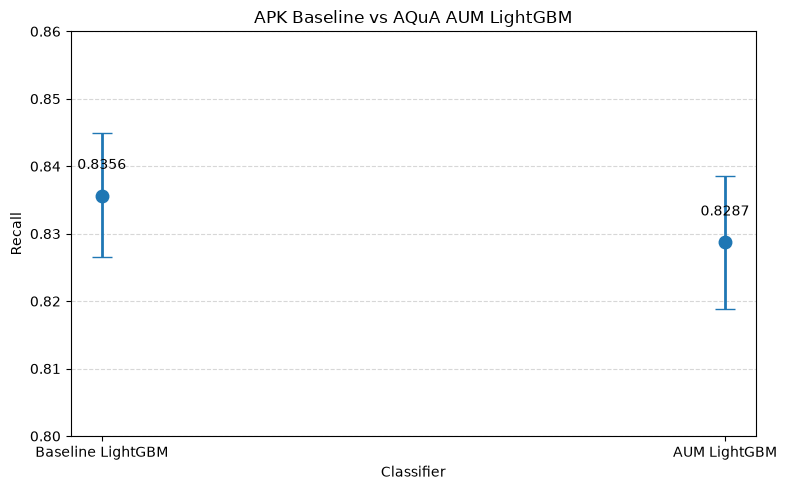

In [120]:
# figure made

import matplotlib.pyplot as plt
import numpy as np

models = ["Baseline LightGBM", "AUM LightGBM"]

recall = [0.8356, 0.8287]

c_lower = [0.8265, 0.8188]
c_upper = [0.8449, 0.8386]

lowerror = np.array(recall) - np.array(c_lower)
uppererror = np.array(c_upper) - np.array(recall)

plt.figure(figsize=(8,5))

plt.errorbar(
    models,
    recall,
    yerr=[lowerror, uppererror],
    fmt="o",
    capsize=7,
    markersize=9,
    linewidth=2
)

plt.ylabel("Recall")
plt.xlabel("Classifier")
plt.title("APK Baseline vs AQuA AUM LightGBM")
plt.ylim(0.80,0.86)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for i, value in enumerate(recall):
    plt.text(i, value + 0.004, f"{value:.4f}", ha="center")

plt.tight_layout()

plt.show()

          

In [121]:
with open("APK_final_checkpoint_results.txt","w") as f:
    f.write(rss.stdout)
    f.write("\n\nErrors:\n")
    f.write(rss.stderr)